In [ ]:
import pandas as pd
from constant import root
author_id_df = pd.read_pickle(root+"paper/authids.pickle")
c5 = pd.read_pickle(root+"paper/num_cited_c5.pickle")
year = pd.read_pickle(root+"paper/year.pickle")
asjcs_df = pd.read_pickle(root+"paper/asjcs.pickle")

In [ ]:
works_df = pd.merge(author_id_df,c5,how="inner",right_index=True, left_index=True,
).merge(year,how="inner", right_index=True, left_index=True,   
).merge(asjcs_df, how="inner",right_index=True,left_index=True,)

works_df.head()

In [ ]:
works_df_asjc = works_df.explode("asjcs")

In [ ]:
fyw = works_df_asjc.groupby(["year", "asjcs"])["c5"].mean()
fyw.reset_index().to_csv("./asjc_year_mean.csv", index=False)
fyw

year  asjcs
1970  1000     12.578043
      1100      3.888784
      1101      2.475936
      1102      2.257331
      1103      3.250752
                 ...    
2024  2614           NaN
      2741           NaN
      3207           NaN
      3303           NaN
      3316           NaN
Name: c5, Length: 17636, dtype: float64

In [ ]:
fwci = works_df_asjc.reset_index().rename(columns={"index":"work_id"})[["work_id","c5", "year", "asjcs"]].merge(
    fyw.reset_index().dropna(),
    how="inner", left_on=["year", "asjcs"], right_on=["year", "asjcs"],
    suffixes=("", "_mean")
    )
fwci["fwci"] = fwci["c5"] / fwci["c5_mean"]
fwci.head()

,work_id,c5,year,asjcs,c5_mean,fwci
0,107,7.0,1997,1902,9.621164,0.727563
1,110,6.0,2000,3109,9.250169,0.648637
2,110,6.0,2000,2610,6.701586,0.895311
3,110,6.0,2000,3100,12.518043,0.479308
4,110,6.0,2000,2604,4.977330,1.205465


In [ ]:
fwci_highest = (
    fwci
    .sort_values(by = "fwci", ascending = False)
    .drop_duplicates("work_id", keep="first").set_index("work_id")
)
fwci_highest.head()

,c5,year,asjcs,c5_mean,fwci
work_id,,,,,
85022158148,24929.0,2016,1105,15.382506,1620.607233
85083951076,15503.0,2015,3310,9.702960,1597.759839
84943645306,20154.0,2015,1804,12.904020,1561.838907
84951834022,12859.0,2015,1700,8.653558,1485.978437
84890330527,21213.0,2013,1105,14.992025,1414.952326


In [ ]:
fwci.shape[0]

111217938

In [ ]:
print(fwci_highest.index.max())
fwci_highest.sample(30)

85194900248


,c5,year,asjcs,c5_mean,fwci
work_id,,,,,
85000948028,45.0,2016,2730,22.586025,1.992382
85057717534,4.0,2018,1100,15.124528,0.264471
84991677290,12.0,2017,1310,21.621086,0.555014
84872139844,1.0,2012,3304,7.931602,0.126078
77957824528,1.0,2008,2202,5.394730,0.185366
32992048,36.0,1999,1304,14.258982,2.524724
24706534,0.0,1989,2719,2.933511,0.000000
85008512355,1.0,2015,2209,14.077046,0.071038
33846370846,10.0,2007,3106,11.706201,0.854248


In [ ]:
fwci_mean = (
    fwci.dropna(subset="fwci")
    .groupby("work_id").mean()
)
fwci_mean.head()

,c5,year,asjcs,c5_mean,fwci
work_id,,,,,
107,7.0,1997.0,1902.0,9.621164,0.727563
110,6.0,2000.0,2855.75,8.361782,0.807180
116,8.0,1997.0,2942.0,7.042289,1.147907
117,24.0,1997.0,2507.5,11.423933,2.103558
118,12.0,1999.0,1602.5,10.716549,1.126253


In [ ]:
fwci_highest

In [ ]:
# works_df_fwci = pd.merge(
#     works_df,
#     fwci_highest["fwci"].dropna(),
#     how="inner", left_index=True, right_index=True,
# )
works_df_fwci = pd.concat(
    [
        works_df.iloc[:100],
        fwci_highest["fwci"].dropna().iloc[:100],
        # fwci_mean["fwci"].dropna()
    ]
)
works_df_fwci.head()

,authids,c5,year,asjcs,fwci
107,"[7004442182, 7004442182, 6603403884, 572032150...",7.0,1997,[1902],1.537073
110,"[7006050637, 6603697521, 6602703231]",6.0,2000,"[3109, 2610, 3100, 2604]",0.217950
116,"[57218153744, 7402496690, 35351983100]",8.0,1997,"[3109, 2613, 3104]",1.342680
117,"[7005148342, 7003508994]",24.0,1997,"[3103, 1912]",2.332574
118,"[6603815313, 7004562485]",12.0,1999,"[1602, 1603]",1.575742


In [ ]:
works_df_fwci.sample(100)

,authids,c5,year,asjcs,fwci
32111708,[21034537800],1.0,1998,"[2732, 3612]",0.379694
26854860,"[7005770321, 7005462778, 7202042160]",0.0,1992,[2700],0.432467
29360169,"[55939244500, 8379907900, 7202651361]",0.0,1995,[3105],1.558211
27498887,"[6508037128, 7404331358, 7004117120, 650759811...",1.0,1993,[3003],3.221902
30089133,[57193532331],0.0,1996,[3500],0.647768
...,...,...,...,...,...
34208497,"[57198236415, 56301966100, 36043762200]",13.0,2000,"[1502, 2502, 2507, 2505]",0.000000
22382531,"[57205005747, 6603618284, 7006459496]",5.0,1985,"[2800, 2728]",0.000000
26337659,"[7403118819, 7401999541]",2.0,1991,[2720],1.355257
21773426,[35570837800],1.0,1984,[2720],0.151803


In [ ]:
works_df.head()

,authids,c5,year,asjcs
107,"[7004442182, 7004442182, 6603403884, 572032150...",7.0,1997,[1902]
110,"[7006050637, 6603697521, 6602703231]",6.0,2000,"[3109, 2610, 3100, 2604]"
116,"[57218153744, 7402496690, 35351983100]",8.0,1997,"[3109, 2613, 3104]"
117,"[7005148342, 7003508994]",24.0,1997,"[3103, 1912]"
118,"[6603815313, 7004562485]",12.0,1999,"[1602, 1603]"


In [ ]:
from constant import Asjcs
from itertools import chain
Asjcs = list(chain.from_iterable(Asjcs.values()))
# bio_asjcs = 
# works_df.explode("asjcs")

[1303,
 1304,
 1305,
 1307,
 1311,
 1312,
 1315,
 2402,
 2804,
 1302,
 1306,
 1308,
 1310,
 1313,
 1314,
 1502,
 2204,
 2403,
 2405,
 2406,
 3002,
 3003,
 3004,
 3005,
 1103,
 1309,
 2702,
 2710,
 2802,
 2803,
 2806,
 3200,
 3201,
 3202,
 3203,
 3204,
 3205,
 3206,
 3207,
 1104,
 1105,
 2302,
 2303,
 2306,
 2309,
 2404,
 2713,
 2718,
 2719]

In [ ]:
works_df_ = works_df.explode("authids")
works_df_ = works_df_[~works_df_["authids"].isin([0,1,2])]
author_count = works_df_["authids"].value_counts()
works_df_ = works_df_[works_df_["authids"].isin(author_count[author_count > 4].index)]

In [ ]:
author_yearly_citation = works_df_.groupby(["authids", "year"]).sum()
author_yearly_citation.head()

c5
authids year       
4       1978    3.0
        1982    2.0
        1988    8.0
        1994   40.0
        1995  383.0

In [ ]:
def zero_to_nan_before_first_nonzero(row):
    mask = (row != 0)
    if not mask.any():
        # 全部0の場合は何もしない（全部Noneにしたいならここを変える）
        return pd.Series([None] * len(row), index=row.index)
    first_nonzero_idx = mask.idxmax()  # 最初にTrueになる列名
    row.iloc[:row.index.get_loc(first_nonzero_idx)] = np.nan
    return row

In [ ]:
import numpy as np
author_year_matrix = author_yearly_citation.reset_index().pivot(
    index="authids",
    columns="year",
    values="c5",
).fillna(0).apply(zero_to_nan_before_first_nonzero, axis=1)

author_year_matrix

year,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
authids,,,,,,,,,,,,,,,,,,,,,
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,0.0,...,5.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.0,44.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,NaN,NaN,2.0,14.0,0.0,0.0,0.0,0.0,0.0,0.0,...,133.0,257.0,823.0,3549.0,0.0,0.0,0.0,0.0,0.0,0.0
6416874,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,26.0,32.0,37.0,11.0,0.0,0.0,0.0,0.0,0.0,0.0
7196578,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,31.0,163.0,698.0,1104.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59153372700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,470.0,111.0,479.0,349.0,0.0,0.0,0.0,0.0,0.0,0.0
59153374600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
59153375100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
author_year_matrix.shape[0] - author_year_matrix[1970].isna().sum()

1292

authids
6504293851    189.0
6505765642    266.0
6505862845    164.0
6506153887    233.0
6506167876    329.0
Name: 1970, dtype: float64
authids
6505765642    186.0
6505817754    282.0
6506004010    236.0
6506056148    225.0
6506345913    152.0
Name: 1971, dtype: float64
authids
6504293851    156.0
6505860559    173.0
6505902633    177.0
6505989127    245.0
6506141607    205.0
Name: 1972, dtype: float64
authids
6505765642    657.0
6505807831    306.0
6505860559    129.0
6506141607    127.0
6506238783    330.0
Name: 1973, dtype: float64
authids
6504519964    183.0
6505653375    156.0
6505865042    778.0
6505942374    117.0
6505967824    149.0
Name: 1974, dtype: float64
authids
6504026482    123.0
6505865042    307.0
6505867171    588.0
6506308274    153.0
6506319812    121.0
Name: 1975, dtype: float64
authids
6504567580    130.0
6505939933    121.0
6506108288    345.0
6506255642    118.0
6506319726    138.0
Name: 1976, dtype: float64
authids
6504400187    154.0
6504643333    199.0
6504701

/tmp/ipykernel_159458/887661224.py:5: RuntimeWarning: invalid value encountered in scalar divide
  return data[data>data.quantile(0.99)].sum() / data.sum()
/tmp/ipykernel_159458/887661224.py:5: RuntimeWarning: invalid value encountered in scalar divide
  return data[data>data.quantile(0.99)].sum() / data.sum()


Series([], Name: 2020, dtype: float64)
Series([], Name: 2021, dtype: float64)


/tmp/ipykernel_159458/887661224.py:5: RuntimeWarning: invalid value encountered in scalar divide
  return data[data>data.quantile(0.99)].sum() / data.sum()
/tmp/ipykernel_159458/887661224.py:5: RuntimeWarning: invalid value encountered in scalar divide
  return data[data>data.quantile(0.99)].sum() / data.sum()


Series([], Name: 2022, dtype: float64)
Series([], Name: 2023, dtype: float64)
Series([], Name: 2024, dtype: float64)


/tmp/ipykernel_159458/887661224.py:5: RuntimeWarning: invalid value encountered in scalar divide
  return data[data>data.quantile(0.99)].sum() / data.sum()
/tmp/ipykernel_159458/887661224.py:5: RuntimeWarning: invalid value encountered in scalar divide
  return data[data>data.quantile(0.99)].sum() / data.sum()


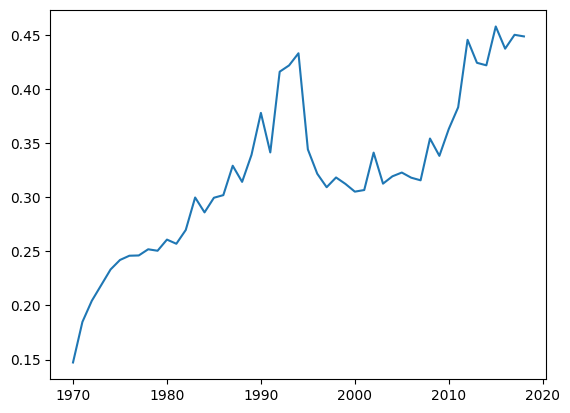

In [ ]:
import matplotlib.pyplot as plt
def plot_citation_monopoly(data):
    data = data.dropna()
    print(data[data>data.quantile(0.99)].head())
    return data[data>data.quantile(0.99)].sum() / data.sum()

monopoly = author_year_matrix.apply(plot_citation_monopoly, axis=0)
plt.plot(monopoly)